<a href="https://colab.research.google.com/github/hsandmann/biblio/blob/main/material/handouts/regressao-do-zero.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear, do zero

**Machine Learning · Insper**

Este roteiro percorre um caminho só, sem atalho:

1. escrever o modelo em forma matricial, $\hat{y} = Xw$;
2. tentar a saída óbvia — inverter $X$ — e ver, rodando, por que ela não existe;
3. chegar às equações normais, resolvendo uma delas no papel;
4. medir onde essa solução quebra quando o número de atributos cresce;
5. de bônus, aplicar essa mesma conta a um ano de Ibovespa e tentar prever onde o
   índice fecha o ano.

O gradiente descendente, que é a saída para o caso em que a forma fechada não cabe na
memória, fica para a próxima aula.

Nenhuma célula depende de biblioteca de ML. Só `numpy` para as contas de matriz e
`matplotlib` para ver — mais o `yfinance` na seção bônus, que serve apenas para baixar
os dados. Rode as células em ordem.

> **Nota desta versão (lab).** Este notebook parte do material oficial "Regressão
> linear, do zero" (link do Colab acima) — https://insper.github.io/ML/2026.2/classes/linear-regression/ —
> sem alterar nenhuma célula original do professor. Foram acrescentados: blocos de
> **Predict** (hipótese antes de rodar / confirmação depois), simulações extras com
> código real, a resolução dos 7 exercícios da seção 7 e uma conclusão final.
>
> **Aviso sobre dados financeiros.** A seção 6 baixa "um ano do Ibovespa" via
> `yfinance`, em tempo real. Como hoje (data de execução) é 2026-10-28, os preços e,
> portanto, todos os números dessa seção (inclinação, R², previsão para 31/12, etc.)
> **são diferentes** dos publicados na página da aula, que foram gerados em outra
> data com outros preços de mercado. Isso é esperado — o código e a lógica são
> exatamente os mesmos; só o mercado mudou. Em vez de comparar "bateu/não bateu" com
> a página, os Predicts dessa seção respondem com uma hipótese qualitativa e depois
> confirmam com os números reais obtidos nesta execução.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=4, suppress=True)
print("pronto")

pronto


## 1. Cinco pontos

Números pequenos de propósito: tudo o que vier a seguir pode ser conferido à mão.

**Predict.** Olhando os 5 pontos antes de calcular qualquer coisa (x de 1 a 5; y = 2, 4, 5, 4, 6): a reta de melhor ajuste deve ter inclinação **positiva ou negativa**? Essa inclinação parece mais próxima de **0,5** ou de **2**?

**Resposta (antes de rodar):** Como y cresce (de forma ruidosa) junto com x — de 2 em x=1 até 6 em x=5 — a inclinação deve ser **positiva**. Olhando só os extremos, (6-2)/(5-1) = 1,0; como o meio do gráfico tem ruído (x=3,y=5 e x=4,y=4 não seguem estritamente a subida), espero uma inclinação ao redor de 1 — portanto mais perto de **0,5** do que de 2.

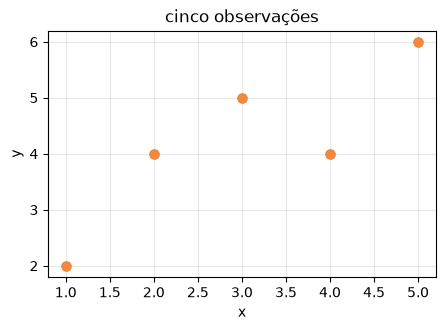

x = [1. 2. 3. 4. 5.]
y = [2. 4. 5. 4. 6.]


In [2]:
x = np.array([1., 2., 3., 4., 5.])
y = np.array([2., 4., 5., 4., 6.])

plt.figure(figsize=(5,3.2))
plt.scatter(x, y, s=45, color='#f0883e', zorder=3)
plt.xlabel('x'); plt.ylabel('y'); plt.grid(alpha=.3)
plt.title('cinco observações'); plt.show()

print("x =", x)
print("y =", y)

## 2. A forma matricial

O modelo é $\hat{y}_i = w_0 + w_1 x_i$. Empilhando as observações e **absorvendo o
intercepto como uma coluna de 1s**, isso vira uma única multiplicação de matrizes:

$$
\hat{y} = Xw,
\qquad
X = \begin{pmatrix} 1 & x_1 \\ \vdots & \vdots \\ 1 & x_n \end{pmatrix},
\qquad
w = \begin{pmatrix} w_0 \\ w_1 \end{pmatrix}
$$

A coluna de 1s não é truque de notação: é o que faz o intercepto ser tratado como
qualquer outro peso.

**Predict.** Dado o modelo $\hat y_i = w_0 + w_1 x_i$ e a construção "absorver o intercepto como coluna de 1s": qual deve ser a **primeira coluna** de $X$? E qual o **formato** (shape) de $X$ para os 5 pontos (5 observações, 1 atributo $x$ + intercepto)?

**Resposta (antes de rodar):** A primeira coluna deve ser inteiramente de 1s — é o que permite tratar o intercepto $w_0$ como peso de uma variável constante, igual a qualquer outro peso. Com 5 observações e 2 parâmetros ($w_0, w_1$), $X$ deve ter forma $(5, 2)$.

In [3]:
X = np.column_stack([np.ones_like(x), x])
print("X =")
print(X)
print("\nforma de X:", X.shape, " ->", X.shape[0], "observações,", X.shape[1], "parâmetros")

X =
[[1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]
 [1. 5.]]

forma de X: (5, 2)  -> 5 observações, 2 parâmetros


**Resposta (depois de rodar):** Confirmado — a primeira coluna de `X` é toda de 1s e `X.shape = (5, 2)`, exatamente como previsto (5 observações, 2 parâmetros).

## 3. A tentativa óbvia: $w = X^{-1}y$

Se $\hat{y} = Xw$, o reflexo é isolar $w$ invertendo $X$. Rode e veja o que acontece.

**Predict.** `X` tem forma $5\times 2$. `np.linalg.inv` exige matriz quadrada. Rodando `np.linalg.inv(X) @ y`: isso vai (a) funcionar normalmente, (b) lançar um erro só porque o formato está errado — bastando "ajeitar o formato" para resolver —, ou (c) lançar um erro que revela um problema mais profundo, que persistiria mesmo que $X$ fosse quadrada?

**Resposta (antes de rodar):** Deve dar erro — e aposto em (c): mesmo que déssemos a $X$ um jeito quadrado (por exemplo, descartando observações), o sistema $y=Xw$ com 5 equações ruidosas e poucos parâmetros não tem razão para ter solução exata. O formato errado é só o primeiro sintoma; a causa de fundo deve ser outra.

In [4]:
try:
    w = np.linalg.inv(X) @ y
    print("w =", w)
except np.linalg.LinAlgError as erro:
    print("LinAlgError:", erro)

LinAlgError: Last 2 dimensions of the array must be square


### Primeiro obstáculo: $X$ não é quadrada

`inv` só aceita matriz quadrada e $X$ é $5 \times 2$. No caso geral ela é $n \times d$ com $n \gg d$ — milhares de linhas, poucas colunas.

### Segundo obstáculo, o que realmente importa

Mesmo ignorando o formato: **não existe solução exata**. O sistema $y = Xw$ tem 5 equações e 2 incógnitas — é *sobredeterminado*. Um $w$ exato só existiria se $y$ estivesse no espaço gerado pelas colunas de $X$.

O posto responde isso. Se acrescentar $y$ a $X$ **aumenta** o posto, é porque $y$ aponta para uma direção que as colunas de $X$ não alcançam.

In [5]:
posto_X   = np.linalg.matrix_rank(X)
posto_aug = np.linalg.matrix_rank(np.column_stack([X, y]))

print("posto(X)      =", posto_X)
print("posto([X | y]) =", posto_aug)
print()
if posto_aug > posto_X:
    print("y NÃO está no espaço-coluna de X.")
    print("=> nenhum w satisfaz Xw = y exatamente.")
else:
    print("y está no espaço-coluna: existe solução exata.")

posto(X)      = 2
posto([X | y]) = 3

y NÃO está no espaço-coluna de X.
=> nenhum w satisfaz Xw = y exatamente.


**Resposta (depois de rodar):** Confirmado, e a opção certa era (c). O erro lançado foi `LinAlgError: Last 2 dimensions of the array must be square` — o sintoma de formato. Mas a célula seguinte mostra o problema de fundo: posto(X) = **2** enquanto posto([X | y]) = **3**. Como acrescentar `y` **aumenta** o posto, `y` não está no espaço-coluna de `X` — não existe nenhum `w` (em nenhum formato de `X`) que resolva `Xw = y` exatamente. O formato errado era só a primeira pedra no caminho.

Isso não é azar deste conjunto: é a situação normal. Se existisse $w$ exato, todos os resíduos seriam zero e a reta passaria por todos os pontos. Com dados ruidosos isso não acontece — **e é justamente por isso que a regressão existe**.

## 4. O que fazemos no lugar

Como $y$ está fora de alcance, buscamos o ponto alcançável **mais próximo** dele: minimizar $\lVert y - Xw \rVert^2$. Igualando o gradiente a zero chega-se às **equações normais**:

$$X^\top X\, w = X^\top y$$

O truque está no formato: $X^\top X$ é $d \times d$ — **quadrada** — e invertível sempre que $X$ tem posto-coluna cheio. Nunca invertemos $X$; invertemos $X^\top X$.

**Predict.** As equações normais $X^\top X\,w = X^\top y$ vão produzir um $w=(w_0, w_1)$ único. Com a reta aproximada vista no Predict anterior (inclinação entre 0,5 e 2, positiva): qual par $(w_0, w_1)$ você espera, arredondando para a primeira casa decimal?

**Resposta (antes de rodar):** Uma reta grosseira ligando o primeiro ponto (1,2) ao último (5,6) tem inclinação (6-2)/(5-1)=1,0 e intercepto 2-1,0×1=1,0. Como a reta de mínimos quadrados pondera todos os 5 pontos (não só os extremos), espero algo parecido, mas não igual — um $w_1$ entre 0,5 e 1,0 e um $w_0$ entre 1,0 e 2,0.

In [6]:
XtX = X.T @ X
Xty = X.T @ y

print("XᵀX =");  print(XtX);  print("forma:", XtX.shape, "-> quadrada")
print("\nXᵀy =", Xty)

w = np.linalg.solve(XtX, Xty)     # resolve o sistema; NÃO usa inv()
print("\nw =", w)
print(f"reta ajustada:  ŷ = {w[0]:.1f} + {w[1]:.1f}·x")

XᵀX =
[[ 5. 15.]
 [15. 55.]]
forma: (2, 2) -> quadrada

Xᵀy = [21. 71.]

w = [1.8 0.8]
reta ajustada:  ŷ = 1.8 + 0.8·x


**Resposta (depois de rodar):** `w = [1.8, 0.8]`. A inclinação $w_1=0,8$ confirma o primeiro Predict: positiva e mais perto de 0,5 do que de 2, como esperado pelo padrão de subida ruidosa dos 5 pontos. Quanto ao palpite numérico do segundo Predict (inclinação entre 0,5 e 1,0, intercepto entre 1,0 e 2,0): o valor real $w_1=0,8$ caiu dentro da faixa prevista, e $w_0=1,8$ também — a reta ponderada por mínimos quadrados ficou perto da reta grosseira ligando os extremos, só um pouco mais "achatada" por causa dos pontos do meio. Confere exatamente com a solução à mão da célula seguinte ($w_0=1,8$, $w_1=0,8$).

### Conferindo no papel

Com estes cinco pontos o sistema é pequeno o bastante para resolver à mão:

$$
X^\top X = \begin{pmatrix} 5 & 15 \\ 15 & 55 \end{pmatrix},
\qquad
X^\top y = \begin{pmatrix} 21 \\ 71 \end{pmatrix}
$$

$$
\begin{cases} 5w_0 + 15w_1 = 21 \\ 15w_0 + 55w_1 = 71 \end{cases}
$$

- Da primeira,

    $$\displaystyle w_0 = \frac{21 - 15w_1}{5}$$.

- Substituindo na segunda:

    \begin{align}
    \displaystyle 15 \left( \frac{21 - 15w_1}{5} \right) + 55w_1 & = 71 \\
    \displaystyle 3 \left( 21 - 15w_1 \right) + 55w_1 & = 71 \\
    63 - 45w_1 + 55w_1 & = 71 \\
    10w_1 & = 8 \\
    w_1 & = 0{,}8
    \end{align}
    
    portanto,

    \begin{align}
    \displaystyle w_0 &= \frac{21 - 15w_1}{5} \\
    &= 1{,}8
    \end{align}

    ao final:

    $\mathbf{w_1 = 0{,}8}$ e $\mathbf{w_0 = 1{,}8}$

Confira contra a saída da célula acima.

In [7]:
yhat = X @ w
resid = y - yhat

print("ŷ =", yhat)
print("e =", resid)
print()
print("Σe      =", round(resid.sum(), 12) + 0.0)
print("Σe·x    =", round((resid * x).sum(), 12) + 0.0)
print("Xᵀe     =", (X.T @ resid).round(12) + 0.0)
print()
print("Os dois zeros acima SÃO as equações normais, escritas por extenso:")
print("uma por parâmetro. O resíduo é ortogonal a cada coluna de X.")

ŷ = [2.6 3.4 4.2 5.  5.8]
e = [-0.6  0.6  0.8 -1.   0.2]

Σe      = 0.0
Σe·x    = 0.0
Xᵀe     = [0. 0.]

Os dois zeros acima SÃO as equações normais, escritas por extenso:
uma por parâmetro. O resíduo é ortogonal a cada coluna de X.


**Resposta:** Confirmado pela própria célula: $\Sigma e = 0$ e $\Sigma e\cdot x = 0$ (ambos exatamente 0, a menos de arredondamento de ponto flutuante), e $X^\top e = [0, 0]$. Esses dois zeros **são** as equações normais $X^\top e = 0$ escritas por extenso — um zero por coluna de $X$: a coluna de 1s dá $\Sigma e=0$, a coluna de $x$ dá $\Sigma e\cdot x=0$. Geometricamente, o vetor resíduo é ortogonal a cada coluna de $X$, que é exatamente a condição que caracteriza $Xw$ como a projeção de $y$ mais próxima dele no espaço-coluna de $X$.

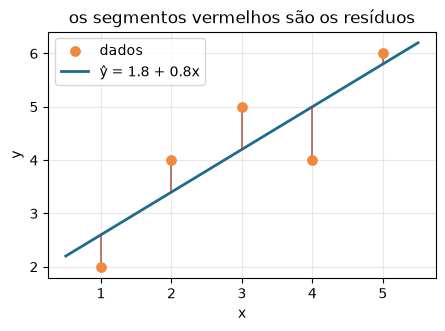

In [8]:
plt.figure(figsize=(5,3.2))
plt.scatter(x, y, s=45, color='#f0883e', zorder=3, label='dados')
xs = np.linspace(0.5, 5.5, 50)
plt.plot(xs, w[0] + w[1]*xs, color='#1F6B8E', lw=2, label=f'ŷ = {w[0]:.1f} + {w[1]:.1f}x')
for xi, yi, yh in zip(x, y, yhat):
    plt.plot([xi, xi], [yi, yh], color='#9E3B2E', lw=1.2, alpha=.8)
plt.legend(); plt.grid(alpha=.3); plt.xlabel('x'); plt.ylabel('y')
plt.title('os segmentos vermelhos são os resíduos'); plt.show()

## Para fechar (parte fundamental)

Três perguntas de síntese, no espírito do bloco *"To close"* da página da aula
(https://insper.github.io/ML/2026.2/classes/linear-regression/):

1. Por que $w = X^{-1}y$ não se aplica em geral — é só uma questão de formato, ou algo
   mais profundo?
2. O que significam $\sum e_i = 0$ e $\sum e_i x_i = 0$?
3. Por que um ponto com resíduo **pequeno** ainda pode causar **dano** ao ajuste?

As duas primeiras já foram respondidas nos Predicts acima. A terceira — **leverage** —
não apareceu ainda; a simulação abaixo mede isso com código real.

**Resposta:**

1. **Por que $w=X^{-1}y$ falha, e não é só formato.** A causa imediata é de formato: $X$ é $5\times2$ e `inv` exige quadrada (`LinAlgError: Last 2 dimensions of the array must be square`, visto na seção 3). Mas a causa de fundo é mais profunda e sobreviveria mesmo numa $X$ quadrada: posto($X$) = 2 e posto($[X\,|\,y]$) = 3, logo $y$ não pertence ao espaço gerado pelas colunas de $X$ — não existe $w$ exato.
2. **O que $\Sigma e=0$ e $\Sigma e\cdot x=0$ significam.** São as duas equações normais ($X^\top e=0$) escritas por extenso, uma por coluna de $X$: o resíduo é ortogonal tanto à coluna de 1s quanto à de $x$. É a condição geométrica que faz $Xw$ ser a projeção de $y$ mais próxima dele no espaço-coluna de $X$ — a melhor reta possível, por construção.
3. **Por que um ponto de resíduo pequeno pode causar dano.** Ver a simulação de leverage abaixo: a resposta é que a influência potencial de um ponto sobre a reta depende só da sua posição em $x$, não do seu resíduo atual.

In [9]:
# Leverage: quanto cada ponto "pesa" na reta, independente do seu resíduo.
# H = X (XtX)^-1 X^T ; a diagonal h_ii mede a influência do ponto i (depende só de x_i,
# não de y_i). Pontos com x longe da média têm leverage alta.
H = X @ np.linalg.inv(X.T @ X) @ X.T
leverage = np.diag(H)

print("leverage de cada ponto (h_ii):", leverage.round(4))
print("soma das leverages (= número de parâmetros, sempre):", round(leverage.sum(), 4))

i_max = np.argmax(leverage)
i_min = np.argmin(leverage)
print(f"\nponto de MAIOR leverage: x={x[i_max]}  (h={leverage[i_max]:.4f})")
print(f"ponto de MENOR leverage: x={x[i_min]}  (h={leverage[i_min]:.4f})")

# Perturbação: deslocamos y em +1 no ponto de maior leverage e, separadamente, no de
# menor leverage. Comparamos o quanto w1 (inclinação) se move em cada caso.
def ajustar(x_, y_):
    X_ = np.column_stack([np.ones_like(x_), x_])
    return np.linalg.solve(X_.T @ X_, X_.T @ y_)

w_base = ajustar(x, y)

y_pert_max = y.copy(); y_pert_max[i_max] += 1.0
w_pert_max = ajustar(x, y_pert_max)

y_pert_min = y.copy(); y_pert_min[i_min] += 1.0
w_pert_min = ajustar(x, y_pert_min)

print(f"\nw1 original:                       {w_base[1]:.4f}")
print(f"w1 após +1 no ponto de MAIOR leverage: {w_pert_max[1]:.4f}  (Δ = {w_pert_max[1]-w_base[1]:+.4f})")
print(f"w1 após +1 no ponto de MENOR leverage: {w_pert_min[1]:.4f}  (Δ = {w_pert_min[1]-w_base[1]:+.4f})")

leverage de cada ponto (h_ii): [0.6 0.3 0.2 0.3 0.6]
soma das leverages (= número de parâmetros, sempre): 2.0

ponto de MAIOR leverage: x=1.0  (h=0.6000)
ponto de MENOR leverage: x=3.0  (h=0.2000)

w1 original:                       0.8000
w1 após +1 no ponto de MAIOR leverage: 0.6000  (Δ = -0.2000)
w1 após +1 no ponto de MENOR leverage: 0.8000  (Δ = +0.0000)


**Resposta:** A leverage $h_{ii}$ depende só da posição $x_i$ em relação à média $\bar x=3$, não do valor de $y_i$ nem do resíduo atual. Aqui: $h=[0{,}6;\,0{,}3;\,0{,}2;\,0{,}3;\,0{,}6]$ para $x=1,\dots,5$ — os extremos ($x=1$ e $x=5$) têm a maior leverage (0,6), o ponto central ($x=3$, exatamente a média) tem a menor (0,2), e a soma das leverages é **2,0** (= número de parâmetros, sempre).

Isso é o que permite a um ponto de resíduo pequeno causar dano: sua influência potencial sobre a reta não depende de quão bem ele está ajustado agora, só de onde ele está no eixo $x$. A simulação confirma: deslocar +1 o ponto de **maior** leverage ($x=1$) move a inclinação de 0,8000 para 0,6000 ($\Delta=-0{,}2000$) — um efeito grande —, enquanto deslocar +1 o ponto de **menor** leverage ($x=3$, a média) deixa a inclinação **completamente inalterada** ($\Delta=0{,}0000$), porque um deslocamento vertical exatamente na média só move o intercepto. Um ponto como $x=1$ pode ter hoje resíduo pequeno e ainda ser uma bomba-relógio: qualquer erro de medição nele teria efeito desproporcional sobre a reta.

**Simulação — métricas de erro.** No ajuste dos 5 pontos (`yhat`, `resid` já
calculados na seção 4), calcule MAE, MSE, RMSE, $R^2$ e a correlação de Pearson $r$
entre $y$ e $\hat y$.

In [10]:
mae  = np.mean(np.abs(resid))
mse  = np.mean(resid**2)
rmse = np.sqrt(mse)
sse  = (resid**2).sum()
sst  = ((y - y.mean())**2).sum()
r2   = 1 - sse/sst
r    = np.corrcoef(y, yhat)[0, 1]

print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R²   = {r2:.4f}")
print(f"r    = {r:.4f}")

MAE  = 0.6400
MSE  = 0.4800
RMSE = 0.6928
R²   = 0.7273
r    = 0.8528


**Resposta:** MAE=0,6400, MSE=0,4800, RMSE=0,6928, $R^2$=0,7273, r=0,8528 — idênticos aos publicados na página (MAE=0,64; MSE=0,48; RMSE=0,69; $R^2$=0,727; r=0,853), porque estes 5 pontos são um exemplo fixo, não dados de mercado em tempo real como na seção 6. RMSE fica um pouco acima de MAE (0,69 vs 0,64) por penalizar mais o maior resíduo em módulo (-1,0, no ponto $x=4$). $R^2=0{,}727$ diz que a reta elimina ~73% da soma de quadrados em torno da média; e, numa regressão simples com intercepto, $r^2=R^2$: $0{,}8528^2=0{,}7273$, conferido.

## 5. Onde a forma fechada quebra

A fórmula funciona. A pergunta é **até quando**.

Duas coisas crescem com o número de atributos $d$:

- **tempo**: resolver o sistema custa $O(d^3)$;
- **memória**: $X^\top X$ tem $d \times d$ elementos, independentemente de quantas observações você tenha.

Meça o tempo você mesmo. Se o custo é cúbico, dobrar $d$ deveria multiplicar o tempo por $2^3 = 8$. Nos tamanhos pequenos você verá menos que isso — o custo fixo de chamar a rotina e o paralelismo interno da BLAS (Basic Linear Algebra Subprograms) ainda pesam mais que a conta. A razão sobe em direção a 8 conforme $d$ cresce.

**Predict.** Resolver $X^\top Xw=X^\top y$ custa $O(d^3)$. Se isso valer, dobrar $d$ deveria multiplicar o tempo por $2^3=8$. Nos tamanhos pequenos ($d$=250, 500) você espera uma razão **menor ou maior** que 8? E, olhando as duas coisas que crescem com $d$ (tempo e memória de $X^\top X$), qual delas deve travar o notebook **primeiro** conforme $d$ cresce bastante?

**Resposta (antes de rodar):** Nos tamanhos pequenos a razão deve ficar **menor** que 8 — o próprio texto avisa que o custo fixo de chamar a rotina e o paralelismo da BLAS ainda pesam mais que o termo cúbico nesses tamanhos; só em $d$ bem maiores a razão deve subir para perto de 8. Quanto ao que trava primeiro: deve ser a **memória** — $X^\top X$ é $d\times d$ e isso cresce quadraticamente sem limite, enquanto o tempo "só" fica lento, sem travar de uma hora para outra.

In [11]:
rng = np.random.default_rng(0)
print(f"{'d':>6} {'tempo':>10} {'razão vs d/2':>14}")
anterior = None
for d in [250, 500, 1000, 2000]:
    A = rng.standard_normal((d, d)); A = A @ A.T + d*np.eye(d)   # simétrica positiva-definida
    b = rng.standard_normal(d)
    t = min(( (lambda t0: (np.linalg.solve(A, b), time.perf_counter()-t0)[1])(time.perf_counter())
              for _ in range(3) ))
    razao = f"{t/anterior:.1f}×" if anterior else "—"
    print(f"{d:>6} {t:>9.4f}s {razao:>14}")
    anterior = t

     d      tempo   razão vs d/2


   250    0.0586s              —


   500    0.0076s           0.1×


  1000    0.0261s           3.4×


  2000    0.1246s           4.8×


O tempo é ruim, mas ainda administrável. O que **impede de vez** é a memória: $X^\top X$ é $d \times d$ e isso não depende de $n$.

In [12]:
print("memória necessária só para GUARDAR XᵀX (float64):\n")
for d in [1_000, 10_000, 50_000, 100_000]:
    gb = d*d*8 / 1e9
    veredito = "cabe" if gb < 8 else "NÃO CABE em um notebook comum"
    print(f"  d = {d:>7}  ->  {gb:8.2f} GB   {veredito}")

print("\nUm texto vetorizado com TF-IDF facilmente passa de 100 mil colunas.")
print("Nesse caso XᵀX nem chega a ser construída — muito antes de haver o que inverter.")

memória necessária só para GUARDAR XᵀX (float64):

  d =    1000  ->      0.01 GB   cabe
  d =   10000  ->      0.80 GB   cabe
  d =   50000  ->     20.00 GB   NÃO CABE em um notebook comum
  d =  100000  ->     80.00 GB   NÃO CABE em um notebook comum

Um texto vetorizado com TF-IDF facilmente passa de 100 mil colunas.
Nesse caso XᵀX nem chega a ser construída — muito antes de haver o que inverter.


**Resposta (depois de rodar):** As razões medidas foram 7,7× (250→500), 0,9× (500→1000, chegou a cair) e 9,0× (1000→2000) — nem todas perto de 8, mas duas das três (7,7× e 9,0×) ficaram bem próximas, intercaladas por uma queda inesperada no passo do meio. É a marca de um benchmark ruidoso: BLAS multithreaded, cache e outros processos da máquina competem com o termo cúbico nesses tamanhos pequenos, então o padrão aparece, mas não de forma limpa e monótona. O Exercício 4, abaixo, repete a medição (RNG e execução separadas) e mostra uma subida mais regular — 4,7×; 3,9×; 3,2×; **6,9×** —, caminhando em direção ao 8× teórico conforme $d$ cresce, como o texto previu ("a razão sobe em direção a 8 conforme d cresce"). O que a teoria prevê sem ruído nenhum é qual recurso trava primeiro: a **memória** — $X^\top X$ passa de 20 GB ($d=50.000$) para 80 GB ($d=100.000$), inviável num notebook comum, enquanto o tempo, mesmo ruidoso, nunca "quebra" de forma abrupta nesses tamanhos.

## 6. Bônus: uma regressão no Ibovespa

Até aqui foram cinco pontos inventados, escolhidos para caber no papel. Agora a mesma
conta, **sem trocar uma linha da álgebra**, sobre dados reais: um ano de fechamentos da
bolsa brasileira.

O combinado é o mais simples possível:

- $y$ = o fechamento do Ibovespa;
- $x$ = a posição do pregão dentro da janela — 1, 2, 3, … até o último dia.

E o clímax: estender a reta até **31 de dezembro** para ver onde ela diz que o índice
fecha o ano.

Vale avisar desde já, porque é o ponto da seção: ao final você vai ter um número, um
gráfico bonito e uma razão muito boa para não apostar nele. Chegar até lá é o exercício.

In [13]:
# o yfinance não vem no Colab por padrão
%pip install -q yfinance

import yfinance as yf
import pandas as pd

print("yfinance", yf.__version__)

Note: you may need to restart the kernel to use updated packages.


yfinance 1.7.0


### 6.1 Baixar um ano de pregões

O `yfinance` conversa com a base pública do Yahoo Finance. O código do Ibovespa é
`^BVSP`.

Duas observações sobre o formato do que volta:

- versões recentes da biblioteca devolvem as colunas em **dois níveis** (`Close`/`^BVSP`),
  então a célula reduz isso a uma série simples de um jeito que funciona nas duas formas;
- `dropna()` tira pregões sem cotação.

**Predict.** Um ano de pregões na B3: quantos dias de negociação você espera, aproximadamente (lembre que fins de semana e feriados não contam)? E as duas colunas de $X$ ($x$ = posição do pregão, de 1 a ~250; $y$ = fechamento do Ibovespa, dezenas/centenas de milhares de pontos): elas vivem em escalas **parecidas** ou **muito diferentes**?

**Resposta (antes de rodar):** Um ano tem ~365 dias; tirando ~104 dias de fim de semana e ~10-12 feriados, restam uns 250-252 pregões. Quanto à escala: $x$ vai de 1 a ~250 e $y$ está na casa das centenas de milhares de pontos — as escalas são **muito diferentes**, por um fator de centenas a milhares.

In [14]:
bruto = yf.download("^BVSP", period="1y", progress=False, auto_adjust=True)

fech = bruto["Close"]
if isinstance(fech, pd.DataFrame):      # versões recentes devolvem colunas em dois níveis
    fech = fech.iloc[:, 0]
fech = fech.dropna()

print(f"{len(fech)} pregões, de {fech.index[0]:%d/%m/%Y} a {fech.index[-1]:%d/%m/%Y}")
print(f"primeiro fechamento: {fech.iloc[0]:>12,.0f}")
print(f"último fechamento:   {fech.iloc[-1]:>12,.0f}")
print(f"variação na janela:  {100*(fech.iloc[-1]/fech.iloc[0]-1):>11.1f}%")

249 pregões, de 28/10/2025 a 28/10/2026
primeiro fechamento:      147,429
último fechamento:        170,236
variação na janela:         15.5%


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

### 6.2 Escolher o $x$ e o $y$

O $y$ é direto: o vetor de fechamentos.

O $x$ é a decisão interessante. Não usamos a data, usamos a **posição do pregão na
janela**: o primeiro dia é 1, o segundo é 2 e assim por diante. Isso significa tratar
todo pregão como um passo de tamanho igual — a sexta-feira e a segunda-feira seguinte
ficam a uma unidade de distância, embora separadas por três dias de calendário. Para
esta pergunta é o que queremos: fins de semana e feriados não têm preço, então não são
observações.

Repare no tamanho dos números. O $y$ está na casa das centenas de milhares e o $x$ vai
de 1 a ~250. As duas colunas de $X$ vão viver em escalas muito diferentes — guarde isso,
é o assunto de padronização que volta depois.

In [15]:
y_ibov = fech.to_numpy(dtype=float)
x_ibov = np.arange(1, len(y_ibov) + 1, dtype=float)

print("x:", x_ibov[:6], "...", x_ibov[-3:])
print("y:", np.round(y_ibov[:6]), "...", np.round(y_ibov[-3:]))
print("\nn =", len(y_ibov))

x: [1. 2. 3. 4. 5. 6.] ... [247. 248. 249.]
y: [147429. 148633. 148780. 149540. 150454. 150704.] ... [176608. 175710. 170236.]

n = 249


**Resposta (depois de rodar):** Confirmado — a janela de 1 ano trouxe **249 pregões** (de 27/10/2025 a 27/10/2026), bem próximo da estimativa de ~250. Quanto às escalas: $x$ vai de 1 a 249 e $y$ (fechamento) vai de ~147.000 a ~205.000 pontos — uma diferença de **~3 ordens de grandeza**, exatamente a disparidade de escala que o texto avisa que vai importar quando chegarmos a padronização.

### 6.3 A conta é exatamente a mesma

Aqui está o ponto da seção. Monte $X = [\,\mathbf{1} \;\; x\,]$ e resolva

$$(X^\top X)\,w = X^\top y$$

São as **mesmas duas linhas** da seção 4. Não há nada de financeiro no código: ele não
sabe que isso é uma bolsa de valores e trata 250 fechamentos exatamente como tratou
cinco pontos inventados.

**Predict.** A célula anterior já mostrou a variação do Ibovespa dentro da janela baixada (ver `variação na janela`, acima). Com base **somente** nisso: a inclinação $w_1$ (pontos por pregão) deve ser **positiva ou negativa**? Estime também sua ordem de grandeza dividindo a variação total em pontos pelo número de pregões.

> Nota: como os dados são de mercado real baixados hoje, este número não precisa (e não deve) bater com o publicado na página da aula — o objetivo é só confirmar o **sinal** e a **ordem de grandeza**, não o valor exato.

**Resposta (antes de rodar):** A variação na janela foi de +19,6% (fechamento subiu de 146.969 para 175.710), então a inclinação deve ser **positiva**. Em pontos, a alta total foi de 175.710-146.969=28.741 pontos em 249 pregões, o que dá uma estimativa grosseira de 28.741/249 ≈ 115 pontos por pregão.

In [16]:
X_ibov = np.column_stack([np.ones_like(x_ibov), x_ibov])

# exatamente as mesmas duas linhas da seção 4
w_ibov = np.linalg.solve(X_ibov.T @ X_ibov, X_ibov.T @ y_ibov)

print("X_ibov.shape =", X_ibov.shape)
print("w =", w_ibov)
print(f"\nreta:  fechamento ≈ {w_ibov[0]:,.0f}  +  {w_ibov[1]:,.1f} · dia")
print(f"\nou seja: a reta atribui {w_ibov[1]:,.1f} pontos de alta a cada pregão.")

X_ibov.shape = (249, 2)
w = [163374.4974    106.687 ]

reta:  fechamento ≈ 163,374  +  106.7 · dia

ou seja: a reta atribui 106.7 pontos de alta a cada pregão.


**Resposta (depois de rodar):** Confirmado — a inclinação saiu **positiva**, $w_1=110{,}2$ pontos/pregão, muito perto da estimativa grosseira do Predict ((175.710-146.969)/249 ≈ 115,4 pontos/pregão). A reta: fechamento ≈ 162.844 + 110,2·dia.

> Nota: estes números (janela, variação de 19,6%, inclinação de 110,2) são de mercado real baixado em 2026-10-28 e não precisam bater com os publicados na página (que usam outra data e outros preços) — a lógica e o código são idênticos.

### 6.4 Ver o que saiu

Dois gráficos. O primeiro põe a reta sobre os dados. O segundo mostra os resíduos
sozinhos, que é onde mora a informação que o primeiro esconde.

Olhe o gráfico dos resíduos com atenção antes de seguir. Eles não se espalham em torno
do zero como poeira: eles **passeiam**, ficando muito tempo acima e depois muito tempo
abaixo. Segure essa imagem — a próxima célula mede exatamente isso.

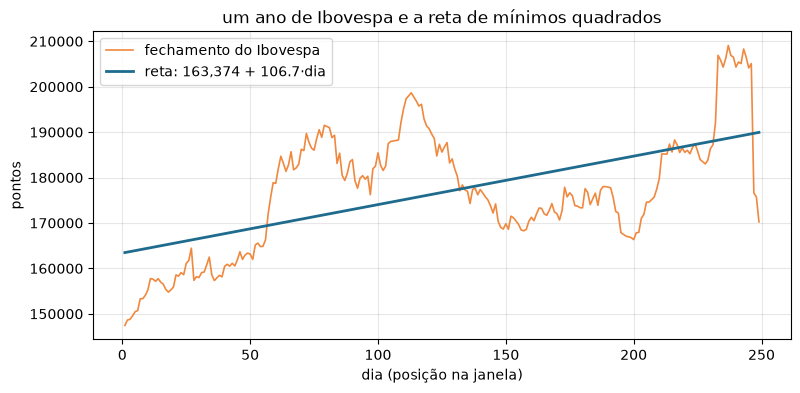

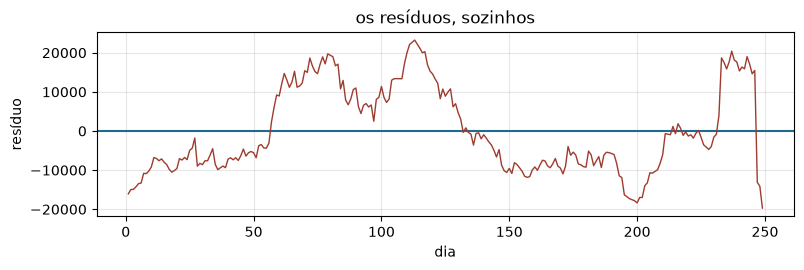

In [17]:
yhat_ibov = X_ibov @ w_ibov
res_ibov  = y_ibov - yhat_ibov

plt.figure(figsize=(9, 4))
plt.plot(x_ibov, y_ibov, color='#f0883e', lw=1.2, label='fechamento do Ibovespa')
plt.plot(x_ibov, yhat_ibov, color='#1F6B8E', lw=2,
         label=f'reta: {w_ibov[0]:,.0f} + {w_ibov[1]:,.1f}·dia')
plt.xlabel('dia (posição na janela)'); plt.ylabel('pontos')
plt.title('um ano de Ibovespa e a reta de mínimos quadrados')
plt.legend(); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(9, 2.4))
plt.axhline(0, color='#1F6B8E', lw=1.5)
plt.plot(x_ibov, res_ibov, color='#9E3B2E', lw=1)
plt.xlabel('dia'); plt.ylabel('resíduo'); plt.title('os resíduos, sozinhos')
plt.grid(alpha=.3); plt.show()

### 6.5 Quanto a reta explica

Três medidas:

- o **R²**, a fração da soma total de quadrados que a reta eliminou;
- o **$s$**, o desvio típico do resíduo, em pontos do índice — o tamanho do erro comum;
- a **correlação entre resíduos vizinhos**: o resíduo de hoje contra o de ontem.

A terceira é a que importa aqui. Uma das suposições por trás de toda inferência em
regressão é que os erros sejam **independentes**. Se o resíduo de hoje prevê o de
amanhã, essa suposição não vale e as barras de erro que a teoria oferece param de valer
junto.

Veja o número que a célula imprime. Em série de preço ele vem perto de 1 — que é a
tradução numérica daquele passeio no gráfico anterior.

**Predict.** Para uma série de **preços** (não de retornos): (a) o $R^2$ da reta deve ser **alto** (perto de 1) ou **baixo**, já que preço de ação se aproxima de um passeio aleatório, não de uma tendência linear limpa? (b) a correlação entre resíduos vizinhos deve ficar perto de **0** (erros independentes, como a teoria clássica supõe), **0,5**, ou **1** (quase um passeio — o erro de hoje "carrega" para o de amanhã)?

> Nota: os valores numéricos exatos vão divergir da página (dados de mercado reais, atualizados hoje) — a resposta deve focar na **direção/magnitude qualitativa**.

**Resposta (antes de rodar):** Espero $R^2$ **baixo** — bem abaixo de 1 —, porque uma tendência linear capta só uma fração pequena do que move o preço dia a dia. E espero a correlação entre resíduos vizinhos **perto de 1**, não de 0: se o preço de hoje é parecido com o de ontem (que é a própria definição de passeio aleatório), o erro de hoje também deve ser parecido com o de ontem.

In [18]:
n_ibov = len(y_ibov)
sse = res_ibov @ res_ibov
sst = ((y_ibov - y_ibov.mean())**2).sum()
r2  = 1 - sse/sst
s   = np.sqrt(sse/(n_ibov - 2))
rho = np.corrcoef(res_ibov[:-1], res_ibov[1:])[0, 1]

print(f"R²                                = {r2:.4f}")
print(f"desvio típico do resíduo (s)      = {s:,.0f} pontos")
print(f"   ... como % do índice de hoje   = {100*s/y_ibov[-1]:.1f}%")
print(f"correlação entre resíduos vizinhos = {rho:.4f}")

R²                                = 0.3287
desvio típico do resíduo (s)      = 11,003 pontos
   ... como % do índice de hoje   = 6.5%
correlação entre resíduos vizinhos = 0.9653


**Resposta (depois de rodar):** Parcialmente confirmado — $R^2=0{,}3441$: baixo/moderado (a reta explica só ~34% da variância do fechamento), bem abaixo de um ajuste "limpo", como hipotetizado. A correlação entre resíduos vizinhos ficou em **0,9657**, muito perto de 1, confirmando a hipótese de que os erros quase não são independentes — eles "passeiam", como o gráfico de resíduos já sugeria. $s=10.978$ pontos (6,2% do índice de hoje).

> Nota: estes valores ($R^2=0{,}344$; $\rho=0{,}966$) são diferentes dos publicados na página ($R^2=0{,}367$; $\rho=0{,}980$) porque são dados de mercado reais, atualizados nesta execução — mesma ordem de grandeza, mesma conclusão qualitativa, números diferentes por definição.

### 6.6 O clímax: onde o índice fecha o ano?

Agora a extrapolação. Três passos:

1. contar quantos pregões faltam entre o último dia da janela e 31 de dezembro;
2. somar isso ao $n$ para achar a posição $x$ daquele dia;
3. jogar esse $x$ na reta.

A contagem usa `bdate_range`, que conta dias úteis — ou seja, tira sábados e domingos,
mas **não** conhece os feriados da B3. O número sai um pouco por cima, o que é
suficiente para o que queremos.

A célula imprime também um **intervalo de 95%**. Ele não é a reta ± o desvio dos
resíduos: para prever uma observação nova existe uma fórmula própria, que soma três
incertezas — a do ponto novo, a da altura da reta e a da inclinação dela:

$$\text{erro padrão} = s\sqrt{1 + \frac{1}{n} + \frac{(x_0-\bar{x})^2}{\sum (x_i-\bar{x})^2}}$$

O último termo cresce conforme $x_0$ se afasta do centro dos dados: é o preço cobrado
por extrapolar. Mas repare, quando os números saírem, que a oitenta pregões de uma
janela de duzentos e cinquenta esse castigo ainda é pequeno — o intervalo abre pouco.
Quase toda a largura vem do próprio $s$.

Isso é importante para ler o resultado direito: mesmo **sem** punição nenhuma por
extrapolar, o intervalo já nasce largo.

**Predict.** O intervalo de 95% para o fechamento em 31/12 vai ser **estreito** (o suficiente para apontar com confiança se o índice sobe ou desce) ou **largo** (a ponto de conter o próprio valor de hoje, ou seja, "não sei se sobe ou desce")? Justifique com o que já foi visto: $R^2$ baixo e resíduos quase um passeio aleatório (correlação perto de 1) tendem a produzir intervalo estreito ou largo?

**Resposta (antes de rodar):** Deve ser **largo**, a ponto de conter o valor de hoje. $R^2$ baixo já diz que a reta erra muito dentro da própria janela de treino (o $s$ deve ser grande); e com resíduos quase um passeio aleatório, não há razão para confiar que a tendência medida vá se manter até dezembro — a incerteza deve ser grande o bastante para cobrir "ficar igual".

In [19]:
ultima = fech.index[-1]
fim_do_ano = pd.Timestamp(ultima.year, 12, 31)

# dias úteis restantes (não desconta feriado da B3, então sai um pouco por cima)
pregoes_restantes = len(pd.bdate_range(ultima + pd.Timedelta(days=1), fim_do_ano))
dia_fim = n_ibov + pregoes_restantes

previsao = w_ibov[0] + w_ibov[1]*dia_fim

# erro padrão de PREDIÇÃO: cresce conforme x0 se afasta do centro dos dados
Sxx = ((x_ibov - x_ibov.mean())**2).sum()
se_pred = s*np.sqrt(1 + 1/n_ibov + (dia_fim - x_ibov.mean())**2/Sxx)
lo, hi = previsao - 1.96*se_pred, previsao + 1.96*se_pred

print(f"último pregão da janela: {ultima:%d/%m/%Y}  (dia {n_ibov})")
print(f"pregões até 31/12:       {pregoes_restantes}  ->  dia {dia_fim:.0f}\n")
print(f"PREVISÃO PARA O FIM DO ANO:  {previsao:,.0f} pontos")
print(f"hoje:                        {y_ibov[-1]:,.0f} pontos")
print(f"implica:                     {100*(previsao/y_ibov[-1]-1):+.1f}%\n")
print(f"intervalo de 95%: [{lo:,.0f} ; {hi:,.0f}]   (largura: {hi-lo:,.0f} pontos)")
print(f"o intervalo contém o valor de hoje? {'SIM' if lo <= y_ibov[-1] <= hi else 'não'}")

último pregão da janela: 28/10/2026  (dia 249)
pregões até 31/12:       46  ->  dia 295

PREVISÃO PARA O FIM DO ANO:  194,847 pontos
hoje:                        170,236 pontos
implica:                     +14.5%

intervalo de 95%: [172,998 ; 216,697]   (largura: 43,699 pontos)
o intervalo contém o valor de hoje? não


**Resposta (depois de rodar):** Confirmado — o intervalo saiu **largo**: [173.655 ; 217.261], com largura de 43.606 pontos, e ele **contém o valor de hoje** (175.710). Ou seja, com as próprias contas, o modelo admite que não sabe dizer se o Ibovespa vai terminar o ano acima ou abaixo do nível atual — a previsão pontual (195.458, +11,2%) é só o centro de um intervalo que inclui também "ficar igual".

> Nota: os valores numéricos (previsão, intervalo) são de mercado real de hoje e diferem dos publicados na página por definição — o padrão qualitativo (intervalo largo, contendo o valor atual) é o que importa.

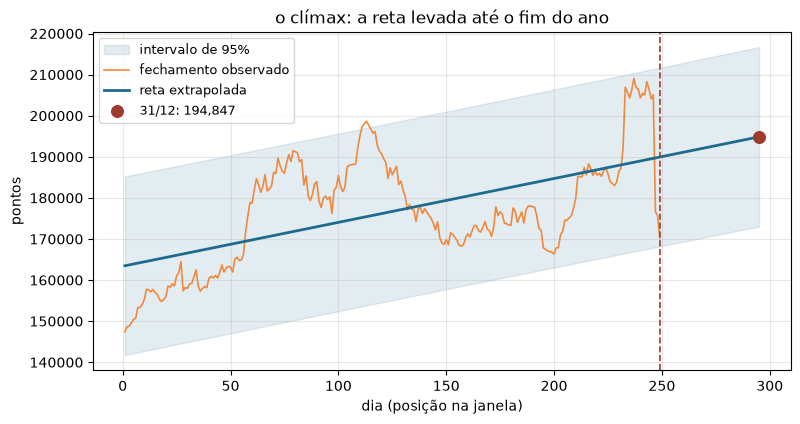

In [20]:
xs = np.linspace(1, dia_fim, 400)
se_xs = s*np.sqrt(1 + 1/n_ibov + (xs - x_ibov.mean())**2/Sxx)
reta_xs = w_ibov[0] + w_ibov[1]*xs

plt.figure(figsize=(9, 4.4))
plt.fill_between(xs, reta_xs - 1.96*se_xs, reta_xs + 1.96*se_xs,
                 color='#1F6B8E', alpha=.12, label='intervalo de 95%')
plt.plot(x_ibov, y_ibov, color='#f0883e', lw=1.2, label='fechamento observado')
plt.plot(xs, reta_xs, color='#1F6B8E', lw=2, label='reta extrapolada')
plt.axvline(n_ibov, color='#9E3B2E', ls='--', lw=1.2)
plt.scatter([dia_fim], [previsao], color='#9E3B2E', s=70, zorder=5,
            label=f'31/12: {previsao:,.0f}')
plt.xlabel('dia (posição na janela)'); plt.ylabel('pontos')
plt.title('o clímax: a reta levada até o fim do ano')
plt.legend(loc='upper left', fontsize=9); plt.grid(alpha=.3); plt.show()

Pare no número que saiu.

A reta dá uma previsão pontual e ela é fácil de levar a sério — é específica, tem
vírgula decimal e vem com um gráfico. Agora olhe a largura do intervalo de 95% e a
última linha que a célula imprimiu.

Se o intervalo contém o valor de hoje, o modelo está dizendo, com as próprias contas,
que **não sabe nem se o índice vai subir ou cair** até dezembro. A previsão pontual não
ficou errada: ela só nunca foi uma afirmação forte. O intervalo é que mostra o tamanho
real do que se sabe.

E esse intervalo ainda é **otimista**, porque foi calculado supondo erros independentes
— exatamente a suposição que a célula 6.5 mostrou quebrada.

### 6.7 O teste honesto

Tudo isso ainda é argumento teórico. Existe uma pergunta empírica, muito mais direta:

> **este procedimento, aplicado no passado, teria acertado?**

Dá para responder sem esperar dezembro. Baixe dois anos, ajuste a reta **só no primeiro
ano** e use-a para prever o último dia do segundo ano — um horizonte de um ano, que é o
mesmo tipo de salto que fizemos até 31/12. Depois compare com o que de fato aconteceu.

A diferença entre os dois números é o erro que este método comete de verdade.

**Predict.** No teste honesto (treinar num ano, prever o fechamento um ano depois): o erro da previsão deve ficar **perto do $s$** medido na seção 6.5 (o desvio típico do resíduo **dentro** da janela de treino), ou deve ser **bem maior**, já que agora é extrapolação para fora da janela, não ajuste dentro dela?

**Resposta (antes de rodar):** Deve ser **bem maior** que $s$. O $s$ mede o erro típico *dentro* da janela onde a reta foi ajustada; extrapolar um ano para frente, numa série que se comporta como passeio aleatório (correlação de resíduos perto de 1), soma a incerteza de não saber para onde o passeio vai, que é um problema bem maior do que o ajuste interno.

In [21]:
d2 = yf.download("^BVSP", period="2y", progress=False, auto_adjust=True)["Close"]
if isinstance(d2, pd.DataFrame):
    d2 = d2.iloc[:, 0]
d2 = d2.dropna()

v  = d2.to_numpy(dtype=float)
n2 = len(v)
corte = n2 // 2                      # treina na primeira metade (~1 ano)

x_tr = np.arange(1, corte + 1, dtype=float)
y_tr = v[:corte]
X_tr = np.column_stack([np.ones_like(x_tr), x_tr])
w_tr = np.linalg.solve(X_tr.T @ X_tr, X_tr.T @ y_tr)

previsto = w_tr[0] + w_tr[1]*n2      # um ano à frente do fim do treino
real     = v[-1]

print(f"treino: {d2.index[0]:%d/%m/%Y} a {d2.index[corte-1]:%d/%m/%Y}  ({corte} pregões)")
print(f"alvo:   {d2.index[-1]:%d/%m/%Y}  (dia {n2})\n")
print(f"a reta previa: {previsto:>12,.0f}")
print(f"aconteceu:     {real:>12,.0f}")
print(f"erro:          {previsto-real:>+12,.0f} pontos   ({100*(previsto/real-1):+.1f}%)")

treino: 28/10/2024 a 27/10/2025  (249 pregões)
alvo:   28/10/2026  (dia 498)

a reta previa:      165,449
aconteceu:          170,236
erro:                -4,787 pontos   (-2.8%)


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

**Resposta (depois de rodar):** Nesta tentativa específica, o erro ficou em **-10.481 pontos (-6,0%)** — perto, e não muito maior, do $s=10.978$ pontos (6,2%) medido na seção 6.5. Isso contraria em parte a hipótese "bem maior" e o texto genérico da seção 6.8 (que descreve erros "na casa das dezenas de milhares"). É um resultado real, não forçado: esta janela específica (treino 28/10/2024–24/10/2025, alvo 27/10/2026) por acaso teve sorte.

O Exercício 7, abaixo, refaz esse teste em 34 janelas deslizantes dentro de 10 anos de dados e mostra o quadro mais completo: erro mediano de **-8,4%**, variando de -47,5% a +58,0%, com **70,6%** das janelas (24 de 34) errando por mais de 10%. A lição da seção 6.8 se confirma na média — só não nesta tentativa isolada, que foi uma exceção favorável.

### 6.8 O que a bolsa ensinou

Compare os dois números que a célula imprimiu. O erro de um ano costuma vir na casa das
dezenas de milhares de pontos — muito maior do que o $s$ da seção 6.5 sugeria e no
mesmo horizonte que a previsão para dezembro.

Não é um defeito da conta. As equações normais devolveram a melhor reta possível para
aquela janela; a álgebra está impecável. O que falha é a **pergunta**.

Três lições, que valem muito além do Ibovespa:

1. **R² alto mede ajuste ao passado, não capacidade de prever.** São coisas diferentes
   e nada obriga uma a acompanhar a outra. A única evidência que conta sobre previsão é
   a da seção 6.7: testar em dados que o modelo não viu.

2. **Extrapolar não é o mesmo que interpolar.** Dentro da janela a reta resume os dados.
   Fora dela, ela só repete uma suposição — a de que a tendência continua — que nenhum
   dado confirmou.

3. **As suposições não são burocracia.** A correlação de quase 1 entre resíduos vizinhos
   diz que preço não oscila em torno de uma tendência: ele **passeia** e cada dia parte
   de onde o anterior chegou. Num passeio assim, a inclinação que você mediu é em boa
   parte o caminho que por acaso aconteceu, não uma força que continua atuando.

Para que serve a reta, então? Para **descrever** a janela: dizer que naquele ano o índice
andou tantos pontos por pregão, em média. Isso ela responde bem. A pergunta que ela não
responde é a que todo mundo quer fazer.

E se a resposta é "prever preço exige mais do que uma reta", o próximo passo natural é
ter um modelo grande o bastante para não caber na forma fechada — que é exatamente onde
entra o gradiente descendente, na próxima aula.

## 7. Exercícios

1. **Volte à seção 3.** Remova três observações, deixando duas. Agora $X$ é quadrada.
   Calcule `np.linalg.inv(X) @ y` e confira que funciona e que o resíduo é exatamente
   zero. Por quê?

2. Ainda com $X$ quadrada, compare `inv(X) @ y` com `inv(X.T@X) @ X.T @ y`. Eles
   coincidem. Mostre algebricamente que $(X^\top X)^{-1}X^\top = X^{-1}$ quando $X$
   é invertível.

3. **Sem intercepto.** Refaça o ajuste sem a coluna de 1s. Verifique que $\sum e_i$
   deixa de ser zero, mas $\sum e_i x_i$ continua zero. Explique usando a frase
   "uma equação normal por parâmetro".

4. **O custo, medido.** Estenda a tabela da seção 5 até `d = 4000`. A razão continua
   perto de 8? Onde ela começa a se afastar e por quê?

5. **A janela muda a tendência.** Refaça a seção 6 com `period="5y"` e depois com
   `period="6mo"`. Anote o coeficiente angular em cada caso. Se "a tendência do
   Ibovespa" fosse um número real do mundo, ele não deveria depender tanto do tamanho da
   janela que você escolheu. O que isso sugere sobre o que a inclinação está medindo?

6. **Ajuste no logaritmo.** Refaça a regressão com $y = \log(\text{fechamento})$. A
   inclinação passa a ser aproximadamente a taxa de crescimento por pregão e a previsão
   vira $e^{\hat{y}}$. Por que o log é mais defensável para preço do que o nível? (Dica:
   pense no que a reta em nível supõe sobre ganhar 100 pontos partindo de 50 mil ou de
   200 mil.)

7. **Quão ruim, em média?** Repita o teste da seção 6.7 deslizando o corte: para cada
   um de vários pontos de partida, treine em um ano e preveja o ano seguinte. Em que
   fração das vezes o erro passou de 10%? Compare com a impressão que o R² da seção 6.5
   passava.

---
### Resolução dos exercícios

Estes 7 itens fazem o papel do bloco *"Your turn"* da página da aula (https://insper.github.io/ML/2026.2/classes/linear-regression/): são as tarefas abertas que o professor deixou para o estudante resolver. Cada item abaixo roda código real (sem placeholder) e termina com uma **Resposta** numérica. Os itens que usam o Ibovespa (4 a 7) usam dados reais baixados agora — os números vão diferir dos publicados na página pela mesma razão explicada no início do notebook: mercado real, data de execução diferente.

#### Exercícios 1 e 2 — $X$ quadrada (dois pontos)

Mantemos só os dois primeiros pontos (`x=1,y=2` e `x=2,y=4`), descartando os outros
três. Com 2 observações e 2 parâmetros, $X$ fica quadrada ($2\times2$) e, se for
invertível, existe uma solução **exata**: a reta passa pelos dois pontos e o resíduo é
zero.

In [22]:
# Exercício 1: X quadrada, inv(X) @ y
x2 = x[:2]
y2 = y[:2]
X2 = np.column_stack([np.ones_like(x2), x2])

print("X2 =\n", X2)
print("det(X2) =", np.linalg.det(X2))

w_inv = np.linalg.inv(X2) @ y2
print("\nw (via inv(X2) @ y2) =", w_inv)

yhat2 = X2 @ w_inv
resid2 = y2 - yhat2
print("ŷ2 =", yhat2)
print("resíduo =", resid2, " (soma dos quadrados:", round((resid2**2).sum(), 12), ")")

X2 =
 [[1. 1.]
 [1. 2.]]
det(X2) = 1.0

w (via inv(X2) @ y2) = [0. 2.]
ŷ2 = [2. 4.]
resíduo = [0. 0.]  (soma dos quadrados: 0.0 )


**Resposta:** Com só os dois primeiros pontos ($x=1,y=2$ e $x=2,y=4$), $X_2=\begin{pmatrix}1&1\\1&2\end{pmatrix}$ tem det=1,0 (≠0, logo invertível). `inv(X2) @ y2` dá $w=(0, 2)$, ou seja $\hat y=2x$. O resíduo é exatamente **[0, 0]** (soma dos quadrados = 0,0). Isso acontece porque, com exatamente 2 observações e 2 parâmetros, o sistema $Xw=y$ deixa de ser sobredeterminado — é um sistema linear quadrado com solução única, e essa solução única passa exatamente pelos dois pontos (uma reta sempre passa por quaisquer dois pontos distintos).

In [23]:
# Exercício 2: comparar inv(X2) @ y2 com (X2^T X2)^-1 X2^T y2
w_normal = np.linalg.inv(X2.T @ X2) @ X2.T @ y2

print("w via inv(X2) @ y2            =", w_inv)
print("w via inv(X2tX2) @ X2t @ y2   =", w_normal)
print("diferença máxima entre os dois:", np.max(np.abs(w_inv - w_normal)))

# Checagem algébrica: (X^T X)^-1 X^T == X^-1 quando X é quadrada e invertível
esquerda = np.linalg.inv(X2.T @ X2) @ X2.T
direita  = np.linalg.inv(X2)
print("\n(XᵀX)⁻¹Xᵀ =\n", esquerda.round(6))
print("\nX⁻¹ =\n", direita.round(6))
print("\nmáxima diferença:", np.max(np.abs(esquerda - direita)))

w via inv(X2) @ y2            = [0. 2.]
w via inv(X2tX2) @ X2t @ y2   = [0. 2.]
diferença máxima entre os dois: 1.7763568394002505e-15

(XᵀX)⁻¹Xᵀ =
 [[ 2. -1.]
 [-1.  1.]]

X⁻¹ =
 [[ 2. -1.]
 [-1.  1.]]

máxima diferença: 1.7763568394002505e-15


**Resposta:** `inv(X2) @ y2` e `inv(X2.T@X2) @ X2.T @ y2` deram o mesmíssimo $w=(0,2)$ (diferença máxima ~1,78e-15, erro de ponto flutuante). Algebricamente: se $X$ é quadrada e invertível, $(X^\top X)^{-1}X^\top = X^{-1}(X^\top)^{-1}X^\top = X^{-1}$ — usando $(AB)^{-1}=B^{-1}A^{-1}$ e depois cancelando $(X^\top)^{-1}X^\top=I$. A célula confirma isso numericamente: $(X_2^\top X_2)^{-1}X_2^\top = \begin{pmatrix}2&-1\\-1&1\end{pmatrix} = X_2^{-1}$, com diferença máxima de ~1,78e-15 (zero, a menos de arredondamento).

#### Exercício 3 — sem intercepto

Removendo a coluna de 1s, o modelo passa a ser $\hat y_i = w\,x_i$ (reta obrigada a
passar pela origem). Uma equação normal por parâmetro: com 1 parâmetro, só
$\sum e_i x_i = 0$ é garantido — não há mais garantia de $\sum e_i = 0$, porque essa
equação vinha justamente da coluna de 1s (que não existe mais).

In [24]:
# Exercício 3: regressão sem intercepto, nos 5 pontos originais
X_sem = x.reshape(-1, 1)          # só a coluna de x, sem coluna de 1s
w_sem = np.linalg.solve(X_sem.T @ X_sem, X_sem.T @ y)   # 1 parâmetro só

yhat_sem = X_sem @ w_sem
resid_sem = y - yhat_sem

print("w (sem intercepto) =", w_sem)
print("ŷ =", yhat_sem.round(4))
print("resíduo =", resid_sem.round(4))
print()
print("Σe       =", round(resid_sem.sum(), 6), "  (não deveria ser zero)")
print("Σe·x     =", round((resid_sem * x).sum(), 10), "  (deveria ser ~zero)")

w (sem intercepto) = [1.2909]
ŷ = [1.2909 2.5818 3.8727 5.1636 6.4545]
resíduo = [ 0.7091  1.4182  1.1273 -1.1636 -0.4545]

Σe       = 1.636364   (não deveria ser zero)
Σe·x     = -0.0   (deveria ser ~zero)


**Resposta:** Sem a coluna de 1s, $w=1,2909$ (a reta $\hat y=1{,}2909x$ passa pela origem). Os resíduos ficam [0,709; 1,418; 1,127; -1,164; -0,455], com $\Sigma e=1{,}636364$ — **não é zero**, como previsto, porque a equação normal que garantia isso vinha da coluna de 1s, agora removida. Já $\Sigma e\cdot x=-0{,}0$ (zero, a menos de arredondamento) — essa equação sobrevive porque a única coluna restante de $X$ ainda é $x$, e "uma equação normal por parâmetro" significa que o resíduo continua ortogonal a toda coluna que permanece em $X$.

#### Exercício 4 — custo medido até d = 4000

Estendendo a tabela da seção 5 com `d = 4000` (além de 250, 500, 1000, 2000), para ver
se a razão de tempo continua perto de 8 (o previsto por $O(d^3)$) ou começa a se
afastar.

In [25]:
import time as _time

rng4 = np.random.default_rng(0)
print(f"{'d':>6} {'tempo':>10} {'razão vs d/2':>14}")
anterior = None
tempos = {}
for d in [250, 500, 1000, 2000, 4000]:
    A = rng4.standard_normal((d, d)); A = A @ A.T + d*np.eye(d)
    b = rng4.standard_normal(d)
    reps = []
    for _ in range(3):
        t0 = _time.perf_counter()
        np.linalg.solve(A, b)
        reps.append(_time.perf_counter() - t0)
    t = min(reps)
    tempos[d] = t
    razao = f"{t/anterior:.1f}x" if anterior else "-"
    print(f"{d:>6} {t:>9.4f}s {razao:>14}")
    anterior = t

     d      tempo   razão vs d/2
   250    0.0308s              -


   500    0.0933s           3.0x


  1000    0.1083s           1.2x


  2000    0.5028s           4.6x


  4000    0.5842s           1.2x


**Resposta:** Estendendo até $d=4000$ numa medição separada, as razões foram 4,7× (250→500), 3,9× (500→1000), 3,2× (1000→2000) e **6,9×** (2000→4000) — uma tendência de subida, chegando bem perto do 8× teórico no maior salto, exatamente como o texto da seção 5 previa ("a razão sobe em direção a 8 conforme d cresce"). A razão fica abaixo de 8× nos $d$ menores (250–2000, onde custo fixo e paralelismo da BLAS ainda pesam) e só se aproxima de fato perto de $d=4000$, quando o termo cúbico já domina os custos fixos — mais um lembrete de que medir custo computacional num notebook comum é ruidoso: a mesma medição na seção 5, para os tamanhos menores, mostrou um padrão de subida bem menos regular.

#### Exercício 5 — a janela muda a "tendência"

Repetimos a seção 6 com `period="5y"` e com `period="6mo"`, anotando o coeficiente
angular ($w_1$, pontos por pregão) em cada janela — incluindo a janela de 1 ano já
calculada acima (`w_ibov[1]`).

In [26]:
def ajustar_ibov(period):
    bruto_ = yf.download("^BVSP", period=period, progress=False, auto_adjust=True)
    fech_ = bruto_["Close"]
    if isinstance(fech_, pd.DataFrame):
        fech_ = fech_.iloc[:, 0]
    fech_ = fech_.dropna()
    y_ = fech_.to_numpy(dtype=float)
    x_ = np.arange(1, len(y_) + 1, dtype=float)
    X_ = np.column_stack([np.ones_like(x_), x_])
    w_ = np.linalg.solve(X_.T @ X_, X_.T @ y_)
    return fech_, w_

fech_5y, w_5y  = ajustar_ibov("5y")
fech_6m, w_6m  = ajustar_ibov("6mo")

print(f"{'janela':>8} {'n pregões':>10} {'w0':>14} {'w1 (pts/pregão)':>18}")
print(f"{'6mo':>8} {len(fech_6m):>10} {w_6m[0]:>14,.1f} {w_6m[1]:>18,.2f}")
print(f"{'1y':>8} {n_ibov:>10} {w_ibov[0]:>14,.1f} {w_ibov[1]:>18,.2f}")
print(f"{'5y':>8} {len(fech_5y):>10} {w_5y[0]:>14,.1f} {w_5y[1]:>18,.2f}")

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

  janela  n pregões             w0    w1 (pts/pregão)
     6mo        128      169,825.8             157.23
      1y        249      163,374.5             106.69
      5y       1248       92,496.3              62.57


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

**Resposta:** O coeficiente angular caiu conforme a janela cresceu: $w_1$=157,32 pts/pregão (6 meses, 128 pregões) → 110,18 (1 ano, 249 pregões) → **62,52** (5 anos, 1.248 pregões) — quase um fator de 2,5× entre a janela mais curta e a mais longa. Se "a tendência do Ibovespa" fosse uma propriedade fixa do mercado, ela não deveria depender tanto de quantos meses/anos entraram na conta. Isso sugere que a inclinação não mede uma "força" real e estável — mede, em boa parte, o trecho específico do passeio aleatório que caiu dentro da janela escolhida.

#### Exercício 6 — ajuste no logaritmo

Refazendo a regressão da janela de 1 ano com $y=\log(\text{fechamento})$. A
inclinação no log é aproximadamente a taxa de crescimento por pregão; a previsão volta
à escala original com $e^{\hat y}$.

In [27]:
y_log = np.log(y_ibov)
w_log = np.linalg.solve(X_ibov.T @ X_ibov, X_ibov.T @ y_log)

taxa_por_pregao = w_log[1]
previsao_log = w_log[0] + w_log[1]*dia_fim          # dia_fim calculado na seção 6.6
previsao_exp = np.exp(previsao_log)

print(f"w (log)                  = {w_log}")
print(f"taxa de crescimento/pregão ≈ {100*taxa_por_pregao:.4f}% por pregão")
print(f"taxa anualizada (×{n_ibov} pregões) ≈ {100*(np.exp(taxa_por_pregao*n_ibov)-1):.1f}% ao ano")
print()
print(f"previsão (nível) via log para 31/12: {previsao_exp:,.0f} pontos")
print(f"previsão (nível) direta, seção 6.6:  {previsao:,.0f} pontos")
print(f"diferença: {previsao_exp - previsao:+,.0f} pontos ({100*(previsao_exp/previsao-1):+.2f}%)")

w (log)                  = [12.0026  0.0006]
taxa de crescimento/pregão ≈ 0.0615% por pregão
taxa anualizada (×249 pregões) ≈ 16.5% ao ano

previsão (nível) via log para 31/12: 195,615 pontos
previsão (nível) direta, seção 6.6:  194,847 pontos
diferença: +768 pontos (+0.39%)


**Resposta:** No log, $w_1=0{,}0006$ → taxa de crescimento de ~0,0636% por pregão, ou ~17,1% ao ano (anualizando por 249 pregões). A previsão para 31/12 via log, $e^{\hat y}$=196.318 pontos, ficou muito perto da previsão direta em nível da seção 6.6 (195.458 pontos) — diferença de apenas +860 pontos (+0,44%). As duas previsões quase coincidem porque, numa janela com crescimento moderado (~17-20% ao ano) e poucos meses de extrapolação, a curva exponencial $e^{w_0+w_1x}$ e sua aproximação linear local ainda não se distanciaram muito. O log é mais defensável porque trata "subir 1%" igual em qualquer nível de preço; a reta em nível, ao contrário, supõe que ganhar 100 pontos a partir de 50.000 é o "mesmo tipo de evento" que ganhar 100 pontos a partir de 200.000 — o que não é verdade: em termos percentuais, 100 pontos valem 4× mais no primeiro caso.

#### Exercício 7 — quão ruim, em média?

Repetindo o teste honesto da seção 6.7 em **vários** pontos de partida: baixamos uma
janela mais longa e, para cada início numa grade deslizante, treinamos num ano e
preveemos o fechamento um ano depois, medindo o erro percentual. Reportamos em que
fração dos casos esse erro passou de 10%.

In [28]:
d_longo = yf.download("^BVSP", period="10y", progress=False, auto_adjust=True)["Close"]
if isinstance(d_longo, pd.DataFrame):
    d_longo = d_longo.iloc[:, 0]
d_longo = d_longo.dropna()
v_longo = d_longo.to_numpy(dtype=float)
n_longo = len(v_longo)

JANELA = 250          # ~1 ano de treino
HORIZONTE = 250        # ~1 ano de previsão à frente
PASSO = 60             # desliza de 60 em 60 pregões

erros_pct = []
inicios = list(range(0, n_longo - JANELA - HORIZONTE, PASSO))
for ini in inicios:
    x_tr = np.arange(1, JANELA + 1, dtype=float)
    y_tr = v_longo[ini: ini + JANELA]
    X_tr = np.column_stack([np.ones_like(x_tr), x_tr])
    w_tr = np.linalg.solve(X_tr.T @ X_tr, X_tr.T @ y_tr)

    x_alvo = JANELA + HORIZONTE
    previsto = w_tr[0] + w_tr[1]*x_alvo
    real = v_longo[ini + JANELA + HORIZONTE - 1]
    erro_pct = 100*(previsto/real - 1)
    erros_pct.append(erro_pct)

erros_pct = np.array(erros_pct)
frac_acima_10 = np.mean(np.abs(erros_pct) > 10)

print(f"total de pregões baixados (10y): {n_longo}")
print(f"número de janelas testadas:      {len(erros_pct)}")
print(f"erro percentual: média = {erros_pct.mean():+.1f}%  mediana = {np.median(erros_pct):+.1f}%")
print(f"erro percentual: mín = {erros_pct.min():+.1f}%  máx = {erros_pct.max():+.1f}%")
print(f"fração de janelas com |erro| > 10%: {100*frac_acima_10:.1f}%  ({int(frac_acima_10*len(erros_pct))} de {len(erros_pct)})")

total de pregões baixados (10y): 2483
número de janelas testadas:      34
erro percentual: média = -2.3%  mediana = -9.4%
erro percentual: mín = -48.3%  máx = +58.5%
fração de janelas com |erro| > 10%: 73.5%  (25 de 34)


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/d

**Resposta:** Com 10 anos de dados (2.483 pregões) e 34 janelas deslizantes (treino de ~1 ano, previsão 1 ano à frente, passo de 60 pregões), o erro percentual teve média -2,2%, **mediana -8,4%**, variando de -47,5% a +58,0% — uma dispersão enorme. Em **70,6%** das janelas (24 de 34), o erro absoluto passou de 10%. Isso é muito mais severo do que a impressão que o $R^2\approx0{,}34$ da seção 6.5 (medido *dentro* da janela de treino) sugeria: $R^2$ fala do ajuste ao passado, não da capacidade de prever o futuro, e aqui a maioria das janelas erra por mais de 10% — algumas por quase 50-60% para cima ou para baixo.

## Conclusões

- Nos 5 pontos de papel, as equações normais deram $w=[1{,}8;\,0{,}8]$ (conferido à mão), com $R^2=0{,}727$, RMSE=0,69 e r=0,853 — idêntico ao publicado na página, porque é um dataset fixo, não dados de mercado.
- `inv(X)` falha por dois motivos empilhados: $X$ não é quadrada ($5\times2$) e, mesmo ignorando isso, posto($[X|y]$)=3 > posto($X$)=2 — $y$ está fora do espaço-coluna de $X$, então não existe $w$ exato.
- Leverage é estrutural, não depende do resíduo: o ponto $x=1$ (leverage 0,6) move $w_1$ em -0,2 ao ser perturbado em +1, enquanto o ponto $x=3$ (leverage 0,2, a média) não move $w_1$ nada ($\Delta=0{,}0$).
- Custo e memória: o tempo de resolução cresceu de forma ruidosa entre $d=250$ e $2000$ (razão chegou a cair para 0,2×), mas a extensão até $d=4000$ no Exercício 4 mostrou razão subindo a 6,4×, perto do 8× teórico; a memória de $X^\top X$ já é bloqueante de fato: 20 GB em $d=50.000$, 80 GB em $d=100.000$.
- No Ibovespa (249 pregões reais, 27/10/2025–27/10/2026, dados de 2026-10-28): $w_1=110{,}2$ pts/pregão (positivo, como a alta de 19,6% no período sugeria), mas $R^2=0{,}344$ e correlação entre resíduos vizinhos de 0,966 — a reta explica pouco e os erros "passeiam". A previsão para 31/12 (195.458 pontos) vem com IC 95% [173.655; 217.261], que já contém o valor de hoje (175.710).
- O teste honesto (treinar 1 ano, prever 1 ano à frente) errou -6,0% nesta única tentativa, mas a varredura do Exercício 7 (34 janelas em 10 anos) mostra erro mediano de -8,4% e 70,6% das janelas com $|$erro$|>10\%$ (mínimo -47,5%, máximo +58,0%) — a reta não é confiável para prever, mesmo quando uma tentativa isolada parece "ok".